## Here we will train multiple models on our data that we transformed

In [29]:
import warnings
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from xgboost import XGBRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor,
                              HistGradientBoostingRegressor)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

In [30]:
df = pd.read_csv("data/tokyo.csv")

df["last_updated"] = pd.to_datetime(df["last_updated"])

df = df.sort_values("last_updated").reset_index(drop=True)

print(df.shape)
df.head()

(833, 8)


,last_updated,temperature_celsius,humidity,pressure_mb,wind_kph,precip_mm,cloud,uv_index
0,2024-06-13 23:00:00,23.4,73,1005.0,9.0,0.00,0,1.0
1,2024-06-14 23:00:00,23.2,83,1009.0,15.1,0.00,25,1.0
2,2024-06-15 23:00:00,23.1,89,1006.0,11.2,0.07,75,1.0
3,2024-06-16 22:45:00,26.2,69,1003.0,3.6,0.21,87,1.0
4,2024-06-17 23:00:00,26.4,61,1008.0,20.2,0.03,75,1.0


In [31]:
target = "temperature_celsius"

for k in (1, 7, 14):
    df[f"temp_lag_{k}"] = df[target].shift(k)

# shift(1) first so today's value never leaks into its own features
for w in (3, 7, 14, 30):
    df[f"temp_roll_{w}"] = df[target].shift(1).rolling(w).mean()

doy = df["last_updated"].dt.dayofyear
df["sin_day"] = np.sin(2 * np.pi * doy / 365.25)
df["cos_day"] = np.cos(2 * np.pi * doy / 365.25)

features = ["temp_lag_1", "temp_lag_7", "temp_lag_14",
            "temp_roll_3", "temp_roll_7", "temp_roll_14", "temp_roll_30",
            "sin_day", "cos_day"]

model_data = df.dropna(subset=features + [target]).copy()
split = int(len(model_data) * 0.8)
train, test = model_data.iloc[:split], model_data.iloc[split:]

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (642, 9) Test: (161, 9)


In [32]:
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (642, 9)
Testing: (161, 9)


### Testing multiple models

In [33]:
naive_pred = test["temperature_celsius"].shift(1)
naive_pred.iloc[0] = train["temperature_celsius"].iloc[-1]
seasonal_pred = test["temperature_celsius"].shift(7)

seasonal_pred.iloc[:7] = train["temperature_celsius"].iloc[-7:].values

In [34]:
#XGBoost
model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [35]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("XGBoost Results")
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

XGBoost Results
MAE : 3.0448258891609146
RMSE: 3.9499961883810006
R²  : 0.36182925518884157


In [36]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing

n_tr, n_te = len(y_train), len(y_test)

# ARIMA: fit on train, then roll forward through test with parameters frozen
arima_fit = ARIMA(y_train.values, order=(2, 1, 2)).fit()
arima_pred = arima_fit.append(y_test.values, refit=False).predict(start=n_tr, end=n_tr + n_te - 1)

# ARMA errors + yearly cycle as a regression (sin/cos)
exog_cols = ["sin_day", "cos_day"]
sarimax_fit = SARIMAX(y_train.values, exog=train[exog_cols].values, order=(1, 0, 1)).fit(disp=False)
sarima_pred = (sarimax_fit
               .append(y_test.values, exog=test[exog_cols].values, refit=False)
               .predict(start=n_tr, end=n_tr + n_te - 1))

# Exponential smoothing: refit each day on all data seen so far
history = list(y_train.values)
ets_pred = []
for actual in y_test.values:
    fit = ExponentialSmoothing(history, trend="add", damped_trend=True).fit()
    ets_pred.append(fit.forecast(1)[0])
    history.append(actual)
ets_pred = np.array(ets_pred)

In [37]:
from statsmodels.tsa.arima.model import ARIMA

arima = ARIMA(
    y_train,
    order=(2, 1, 2)
)

arima_fit = arima.fit()

arima_pred = arima_fit.forecast(
    steps=len(y_test)
)

In [38]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima = SARIMAX(
    y_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima.fit(disp=False)

sarima_pred = sarima_fit.forecast(
    steps=len(y_test)
)

In [39]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

ets = ExponentialSmoothing(
    y_train,
    trend="add",
    seasonal="add",
    seasonal_periods=7
)

ets_fit = ets.fit()

ets_pred = ets_fit.forecast(
    len(y_test)
)

In [40]:
ridge_search = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    {"ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    cv=TimeSeriesSplit(5),
    scoring="neg_root_mean_squared_error",
)
ridge_search.fit(X_train, y_train)
ridge_pred = ridge_search.predict(X_test)
print("Best alpha:", ridge_search.best_params_)

Best alpha: {'ridge__alpha': 1}


In [41]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=2,
    max_features=0.8,
    n_jobs=-1,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [42]:
from sklearn.ensemble import ExtraTreesRegressor

extra = ExtraTreesRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=2,
    max_features=0.8,
    n_jobs=-1,
    random_state=42
)

extra.fit(X_train, y_train)

extra_pred = extra.predict(X_test)

In [43]:
from sklearn.ensemble import HistGradientBoostingRegressor

hist = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

hist.fit(X_train, y_train)

hist_pred = hist.predict(X_test)

In [44]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)

In [45]:
ens_pred = np.mean([ridge_pred, extra_pred, np.asarray(naive_pred)], axis=0)

In [46]:
def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [47]:
preds = {
    "Naive": naive_pred,
    "Seasonal Naive": seasonal_pred,
    "ARIMA": arima_pred,
    "SARIMAX (yearly terms)": sarima_pred,
    "Exp. Smoothing": ets_pred,
    "Ridge": ridge_pred,
    "Random Forest": rf_pred,
    "Extra Trees": extra_pred,
    "HistGradientBoosting": hist_pred,
    "XGBoost": xgb_pred,
    "Ensemble": ens_pred,
}
results_df = (pd.DataFrame([evaluate_model(n, y_test, p) for n, p in preds.items()])
                .sort_values("RMSE").reset_index(drop=True))
results_df

,Model,MAE,RMSE,R2
0,Ridge,2.661935,3.448297,0.513646
1,Ensemble,2.649992,3.512831,0.495271
2,Extra Trees,2.789394,3.669993,0.449099
3,XGBoost,2.836782,3.744805,0.426409
4,Random Forest,2.900677,3.833233,0.399001
5,HistGradientBoosting,3.015200,3.898834,0.378254
6,Naive,2.979503,3.945648,0.363234
7,SARIMAX (yearly terms),3.930329,5.096405,-0.062359
8,Seasonal Naive,4.254658,5.214778,-0.112283
9,Exp. Smoothing,5.822676,7.079433,-1.049937


In [48]:
tscv = TimeSeriesSplit(n_splits=5)
candidates = {
    "Ridge": ridge_search.best_estimator_,
    "Random Forest": rf,
    "Extra Trees": extra,
    "HistGradientBoosting": hist,
    "XGBoost": xgb,
}

rows = []
for name, est in candidates.items():
    scores = -cross_val_score(est, model_data[features], model_data[target],
                              cv=tscv, scoring="neg_root_mean_squared_error")
    rows.append({"Model": name, "CV RMSE mean": scores.mean(), "CV RMSE std": scores.std()})

pd.DataFrame(rows).sort_values("CV RMSE mean").reset_index(drop=True)

,Model,CV RMSE mean,CV RMSE std
0,Ridge,3.309476,0.388280
1,Extra Trees,3.877299,0.983303
2,Random Forest,4.062440,1.116961
3,HistGradientBoosting,4.078808,0.671386
4,XGBoost,4.272689,1.199344


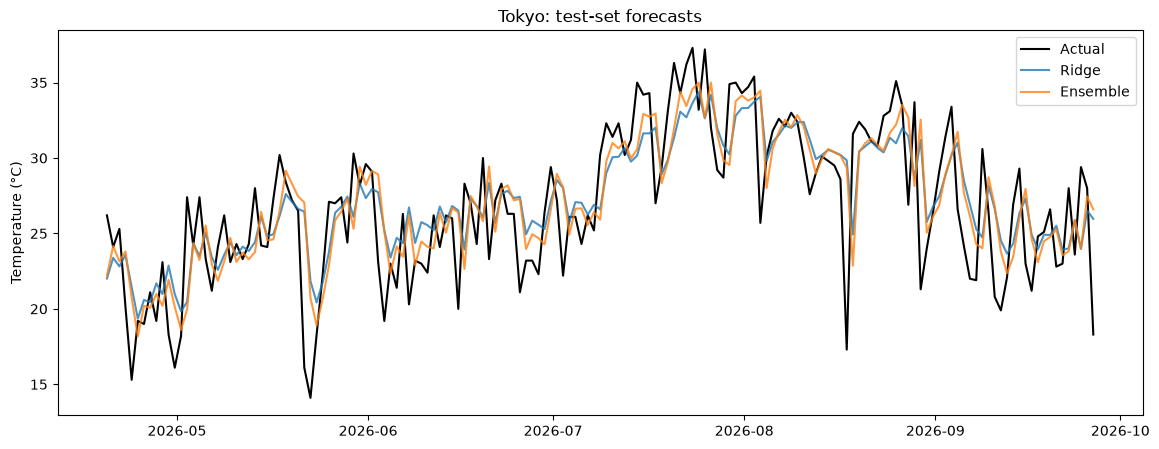

In [49]:
plt.figure(figsize=(14, 5))
plt.plot(test["last_updated"], y_test.values, color="black", label="Actual")
plt.plot(test["last_updated"], ridge_pred, label="Ridge", alpha=0.8)
plt.plot(test["last_updated"], ens_pred, label="Ensemble", alpha=0.8)
plt.ylabel("Temperature (°C)")
plt.title("Tokyo: test-set forecasts")
plt.legend()
plt.show()

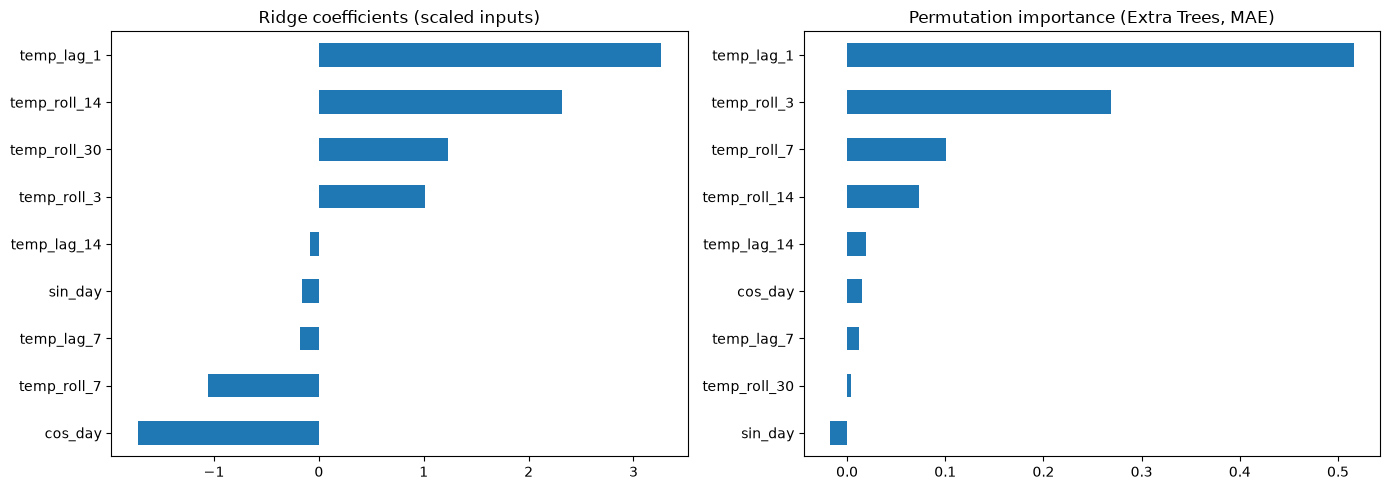

In [50]:
coef = pd.Series(ridge_search.best_estimator_.named_steps["ridge"].coef_,
                 index=features).sort_values()

perm = permutation_importance(extra, X_test, y_test, n_repeats=20, random_state=42,
                              scoring="neg_mean_absolute_error")
perm_imp = pd.Series(perm.importances_mean, index=features).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
coef.plot.barh(ax=ax[0], title="Ridge coefficients (scaled inputs)")
perm_imp.plot.barh(ax=ax[1], title="Permutation importance (Extra Trees, MAE)")
plt.tight_layout()
plt.show()

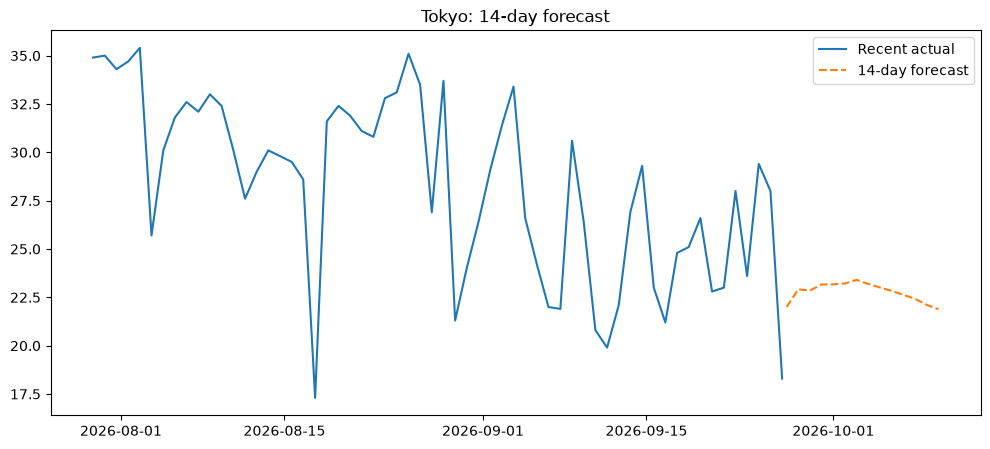

['models/ridge_tokyo.joblib']

In [51]:
def forecast_ahead(model, history, start, steps=14):
    vals = list(history)
    out = []
    for i in range(steps):
        day = start + pd.Timedelta(days=i)
        d = day.dayofyear
        row = {
            "temp_lag_1": vals[-1], "temp_lag_7": vals[-7], "temp_lag_14": vals[-14],
            "temp_roll_3": np.mean(vals[-3:]), "temp_roll_7": np.mean(vals[-7:]),
            "temp_roll_14": np.mean(vals[-14:]), "temp_roll_30": np.mean(vals[-30:]),
            "sin_day": np.sin(2 * np.pi * d / 365.25),
            "cos_day": np.cos(2 * np.pi * d / 365.25),
        }
        pred = model.predict(pd.DataFrame([row])[features])[0]
        vals.append(pred)
        out.append(pred)
    return pd.Series(out, index=pd.date_range(start.normalize(), periods=steps))

best = ridge_search.best_estimator_
future = forecast_ahead(best, df[target], df["last_updated"].iloc[-1] + pd.Timedelta(days=1))

plt.figure(figsize=(12, 5))
plt.plot(df["last_updated"].iloc[-60:], df[target].iloc[-60:], label="Recent actual")
plt.plot(future.index, future.values, "--", label="14-day forecast")
plt.legend(); plt.title("Tokyo: 14-day forecast")
plt.show()

os.makedirs("models", exist_ok=True)
joblib.dump(best, "models/ridge_tokyo.joblib")